# Section 3. ELS Payoff Logic

In [1]:
# ============================================================
# Section 3. ELS Payoff Logic
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from dataclasses import dataclass

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", "{:,.6f}".format)

SEED = 42
np.random.seed(SEED)

In [2]:
# ============================================================
# 3-0. Project Directory Setting
# ============================================================

PROJECT_NAME = "ELS hege 5.19"
CURRENT_DIR = Path.cwd()


def find_project_dir(project_name=PROJECT_NAME):
    """
    Resolve the local project folder from the notebook folder, a subfolder,
    or the parent workspace folder.
    """
    current = Path.cwd().resolve()

    if current.name == project_name:
        return current

    for parent in current.parents:
        if parent.name == project_name:
            return parent

    for base in [current, *current.parents]:
        candidate = base / project_name
        if candidate.exists():
            return candidate.resolve()

    return current / project_name


PROJECT_DIR = find_project_dir()

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "output"
FIGURE_DIR = PROJECT_DIR / "figures"
CODE_DIR = PROJECT_DIR

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

KOSPI200_PATH = DATA_DIR / "kospi200_close_new.csv"

print("CURRENT_DIR:", CURRENT_DIR)
print("PROJECT_DIR:", PROJECT_DIR)
print("DATA_DIR:", DATA_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("FIGURE_DIR:", FIGURE_DIR)
print("CODE_DIR:", CODE_DIR)
print("KOSPI200_PATH:", KOSPI200_PATH)
print("Data file exists:", KOSPI200_PATH.exists())


CURRENT_DIR: c:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
PROJECT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
DATA_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\data
OUTPUT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output
FIGURE_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures
CODE_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
KOSPI200_PATH: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\data\kospi200_close_new.csv
Data file exists: True


In [3]:
# ============================================================
# 3-1. ELS Product Specification
# ============================================================

@dataclass
class ELSProduct:
    underlying: str
    notional: float
    issue_date: str
    maturity_date: str
    payment_date: str
    
    annual_coupon: float
    maturity_years: float
    
    autocall_dates: list
    autocall_barriers: list
    
    knock_in_barrier: float
    max_loss_rate: float


els = ELSProduct(
    underlying="KOSPI200",
    notional=10_000_000_000,  # 100억원
    
    issue_date="2026-05-14",
    maturity_date="2029-05-09",
    payment_date="2029-05-14",
    
    annual_coupon=0.097,
    maturity_years=3.0,
    
    autocall_dates=[
        "2026-11-10",
        "2027-05-10",
        "2027-11-09",
        "2028-05-09",
        "2028-11-09",
        "2029-05-09",
    ],
    
    autocall_barriers=[0.85, 0.85, 0.85, 0.80, 0.75, 0.70],
    
    knock_in_barrier=0.35,
    max_loss_rate=-1.00
)

NOTIONAL = els.notional
S0 = 100
TRADING_DAYS = 252
RISK_FREE_RATE = 0.03
PRINCIPAL_DAILY_RATE = 0.03 / 365

els

ELSProduct(underlying='KOSPI200', notional=10000000000, issue_date='2026-05-14', maturity_date='2029-05-09', payment_date='2029-05-14', annual_coupon=0.097, maturity_years=3.0, autocall_dates=['2026-11-10', '2027-05-10', '2027-11-09', '2028-05-09', '2028-11-09', '2029-05-09'], autocall_barriers=[0.85, 0.85, 0.85, 0.8, 0.75, 0.7], knock_in_barrier=0.35, max_loss_rate=-1.0)

In [4]:
# ============================================================
# 3-2. Load Section 2 Outputs
# ============================================================

paths_path = OUTPUT_DIR / "mc_paths.npy"
sim_dates_path = OUTPUT_DIR / "sim_dates.csv"
autocall_result_path = OUTPUT_DIR / "autocall_result.csv"
autocall_schedule_path = OUTPUT_DIR / "autocall_schedule.csv"
market_params_path = OUTPUT_DIR / "market_params.csv"

paths = np.load(paths_path)

sim_dates = pd.read_csv(sim_dates_path)
sim_dates["Date"] = pd.to_datetime(sim_dates["Date"])
sim_dates = pd.DatetimeIndex(sim_dates["Date"])

autocall_result = pd.read_csv(autocall_result_path)
autocall_schedule = pd.read_csv(autocall_schedule_path)

autocall_schedule["target_date"] = pd.to_datetime(autocall_schedule["target_date"])
autocall_schedule["sim_date"] = pd.to_datetime(autocall_schedule["sim_date"])

market_params = pd.read_csv(market_params_path).iloc[0].to_dict()

print("paths shape:", paths.shape)
print("sim_dates:", sim_dates[0], "~", sim_dates[-1])
display(autocall_schedule)
display(autocall_result.head())
display(market_params)

paths shape: (10000, 780)
sim_dates: 2026-05-14 00:00:00 ~ 2029-05-09 00:00:00


,autocall_no,target_date,sim_date,time_index,year_fraction,barrier
0,1,2026-11-10,2026-11-10,128,0.500000,0.850000
1,2,2027-05-10,2027-05-10,257,1.000000,0.850000
2,3,2027-11-09,2027-11-09,388,1.500000,0.850000
3,4,2028-05-09,2028-05-09,518,2.000000,0.800000
4,5,2028-11-09,2028-11-09,650,2.500000,0.750000
5,6,2029-05-09,2029-05-09,779,3.000000,0.700000


,autocall_occurred,autocall_no,autocall_index,knock_in_occurred,final_price,min_price
0,True,1,128,False,85.148390,73.958330
1,True,1,128,False,382.028553,99.089556
2,True,1,128,False,130.545363,83.432437
3,True,1,128,False,88.593817,77.338565
4,True,1,128,False,73.937730,73.937730


{'S0': 100.0,
 'MU': 0.03,
 'SIGMA': 0.2720417549189577,
 'RISK_FREE_RATE': 0.03,
 'TRADING_DAYS': 252.0,
 'vol_full': 0.2473644004616745,
 'vol_1y': 0.3737365451878063,
 'vol_3y': 0.2720417549189577}

1. 조기상환 발생 시:
   payoff = 원금 × (1 + 연쿠폰 × 경과연수)

2. 만기까지 조기상환이 없고, 만기평가가격 >= 70%:
   payoff = 원금 × (1 + 연쿠폰 × 3년)

3. 만기까지 조기상환이 없고, 만기평가가격 < 70%:
   a. 낙인 미발생:
      payoff = 원금 × (1 + 연쿠폰 × 3년)
   
   b. 낙인 발생:
      payoff = 원금 × (S_T / S0)

In [5]:
# ============================================================
# 3-3. Payoff Assumptions
# ============================================================

payoff_assumptions = {
    "issuer_perspective": "payoff is liability / cash outflow to investor",
    "early_redemption": "notional * (1 + annual_coupon * elapsed_years)",
    "maturity_success": "notional * (1 + annual_coupon * 3)",
    "no_knock_in_at_maturity": "notional * (1 + annual_coupon * 3)",
    "knock_in_and_final_below_barrier": "notional * (S_T / S0)",
    "final_barrier": "70% of initial price",
}

payoff_assumptions

{'issuer_perspective': 'payoff is liability / cash outflow to investor',
 'early_redemption': 'notional * (1 + annual_coupon * elapsed_years)',
 'maturity_success': 'notional * (1 + annual_coupon * 3)',
 'no_knock_in_at_maturity': 'notional * (1 + annual_coupon * 3)',
 'knock_in_and_final_below_barrier': 'notional * (S_T / S0)',
 'final_barrier': '70% of initial price'}

In [6]:
# ============================================================
# 3-4. ELS Payoff Function
# ============================================================

def calculate_els_payoff(
    paths,
    autocall_schedule,
    notional,
    S0,
    annual_coupon,
    knock_in_barrier,
    maturity_years
):
    """
    Step-down KI ELS의 path별 payoff를 계산한다.
    
    투자자 관점:
    - payoff는 투자자가 받는 금액
    
    발행자 관점:
    - payoff는 발행자가 지급해야 하는 liability
    
    Parameters
    ----------
    paths : np.ndarray
        shape = (n_paths, n_steps + 1)
    autocall_schedule : pd.DataFrame
        autocall_no, time_index, year_fraction, barrier 포함
    notional : float
        발행금액
    S0 : float
        최초기준가격, 정규화 기준 100
    annual_coupon : float
        연 쿠폰
    knock_in_barrier : float
        예: 0.35
    maturity_years : float
        예: 3.0
    
    Returns
    -------
    payoff_df : pd.DataFrame
        path별 payoff 결과
    """
    
    n_paths = paths.shape[0]
    
    payoff = np.zeros(n_paths)
    payoff_type = np.array([""] * n_paths, dtype=object)
    
    autocall_occurred = np.zeros(n_paths, dtype=bool)
    autocall_no = np.zeros(n_paths, dtype=int)
    settlement_index = np.full(n_paths, paths.shape[1] - 1, dtype=int)
    elapsed_years = np.full(n_paths, maturity_years, dtype=float)
    
    # 1. 조기상환 및 만기상환 barrier 체크
    for _, row in autocall_schedule.iterrows():
        obs_no = int(row["autocall_no"])
        obs_idx = int(row["time_index"])
        barrier_level = float(row["barrier"]) * S0
        year_frac = float(row["year_fraction"])
        
        not_yet_called = ~autocall_occurred
        hit = paths[:, obs_idx] >= barrier_level
        newly_called = not_yet_called & hit
        
        if newly_called.sum() > 0:
            payoff[newly_called] = notional * (1 + annual_coupon * year_frac)
            payoff_type[newly_called] = f"autocall_{obs_no}"
            
            autocall_occurred[newly_called] = True
            autocall_no[newly_called] = obs_no
            settlement_index[newly_called] = obs_idx
            elapsed_years[newly_called] = year_frac
    
    # 2. 조기상환이 되지 않은 path 처리
    no_autocall = ~autocall_occurred
    
    final_price = paths[:, -1]
    min_price = paths.min(axis=1)
    
    ki_level = S0 * knock_in_barrier
    knock_in_occurred = min_price <= ki_level
    
    # 조기상환 안 됐고, 낙인 미발생이면 원금 + 만기쿠폰 지급
    no_autocall_no_ki = no_autocall & (~knock_in_occurred)
    
    payoff[no_autocall_no_ki] = notional * (1 + annual_coupon * maturity_years)
    payoff_type[no_autocall_no_ki] = "maturity_no_knock_in"
    
    # 조기상환 안 됐고, 낙인 발생이면 final performance에 연동
    no_autocall_ki = no_autocall & knock_in_occurred
    
    payoff[no_autocall_ki] = notional * (final_price[no_autocall_ki] / S0)
    payoff_type[no_autocall_ki] = "maturity_knock_in_loss"
    
    payoff_df = pd.DataFrame({
        "path_id": np.arange(n_paths),
        "autocall_occurred": autocall_occurred,
        "autocall_no": autocall_no,
        "settlement_index": settlement_index,
        "elapsed_years": elapsed_years,
        "knock_in_occurred": knock_in_occurred,
        "final_price": final_price,
        "min_price": min_price,
        "payoff_type": payoff_type,
        "investor_payoff": payoff,
        "issuer_cash_outflow": payoff,
        "investor_return_rate": payoff / notional - 1,
    })
    
    return payoff_df

In [7]:
# ============================================================
# 3-5. Calculate ELS Payoff
# ============================================================

payoff_df = calculate_els_payoff(
    paths=paths,
    autocall_schedule=autocall_schedule,
    notional=NOTIONAL,
    S0=S0,
    annual_coupon=els.annual_coupon,
    knock_in_barrier=els.knock_in_barrier,
    maturity_years=els.maturity_years
)

display(payoff_df.head())
display(payoff_df.tail())

,path_id,autocall_occurred,autocall_no,settlement_index,elapsed_years,knock_in_occurred,final_price,min_price,payoff_type,investor_payoff,issuer_cash_outflow,investor_return_rate
0,0,True,1,128,0.500000,False,85.148390,73.958330,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
1,1,True,1,128,0.500000,False,382.028553,99.089556,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
2,2,True,1,128,0.500000,False,130.545363,83.432437,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
3,3,True,1,128,0.500000,False,88.593817,77.338565,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
4,4,True,1,128,0.500000,False,73.937730,73.937730,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500


,path_id,autocall_occurred,autocall_no,settlement_index,elapsed_years,knock_in_occurred,final_price,min_price,payoff_type,investor_payoff,issuer_cash_outflow,investor_return_rate
9995,9995,True,1,128,0.500000,False,67.094883,60.283054,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
9996,9996,True,1,128,0.500000,False,98.451087,79.432242,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
9997,9997,False,0,779,3.000000,True,50.229018,34.998732,maturity_knock_in_loss,"5,022,901,846.644485","5,022,901,846.644485",-0.497710
9998,9998,True,1,128,0.500000,False,58.875144,57.847763,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
9999,9999,True,1,128,0.500000,False,68.743016,52.894613,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500


In [8]:
# ============================================================
# 3-6. Payoff Result Check
# ============================================================

print("Number of paths:", len(payoff_df))
print("Payoff min:", payoff_df["investor_payoff"].min())
print("Payoff max:", payoff_df["investor_payoff"].max())
print("Return min:", payoff_df["investor_return_rate"].min())
print("Return max:", payoff_df["investor_return_rate"].max())

payoff_df["payoff_type"].value_counts()

Number of paths: 10000
Payoff min: 1782028712.1675198
Payoff max: 12910000000.0
Return min: -0.821797128783248
Return max: 0.2909999999999999


payoff_type
autocall_1                8038
autocall_2                 607
maturity_no_knock_in       458
autocall_3                 272
autocall_4                 202
autocall_5                 164
maturity_knock_in_loss     130
autocall_6                 129
Name: count, dtype: int64

In [9]:
# ============================================================
# 3-7. Payoff Summary by Type
# ============================================================

payoff_summary_by_type = (
    payoff_df
    .groupby("payoff_type")
    .agg(
        count=("path_id", "count"),
        avg_payoff=("investor_payoff", "mean"),
        min_payoff=("investor_payoff", "min"),
        max_payoff=("investor_payoff", "max"),
        avg_return=("investor_return_rate", "mean"),
        min_return=("investor_return_rate", "min"),
        max_return=("investor_return_rate", "max"),
        avg_final_price=("final_price", "mean"),
        avg_min_price=("min_price", "mean"),
    )
    .reset_index()
)

payoff_summary_by_type["probability"] = payoff_summary_by_type["count"] / len(payoff_df)

payoff_summary_by_type

,payoff_type,count,avg_payoff,min_payoff,max_payoff,avg_return,min_return,max_return,avg_final_price,avg_min_price,probability
0,autocall_1,8038,"10,485,000,000.000000","10,485,000,000.000000","10,485,000,000.000000",0.048500,0.048500,0.048500,115.380987,75.201046,0.803800
1,autocall_2,607,"10,970,000,000.000000","10,970,000,000.000000","10,970,000,000.000000",0.097000,0.097000,0.097000,103.381453,66.811773,0.060700
2,autocall_3,272,"11,455,000,000.000000","11,455,000,000.000000","11,455,000,000.000000",0.145500,0.145500,0.145500,98.848440,63.834298,0.027200
3,autocall_4,202,"11,940,000,000.000000","11,940,000,000.000000","11,940,000,000.000000",0.194000,0.194000,0.194000,93.622477,60.264341,0.020200
4,autocall_5,164,"12,425,000,000.000000","12,425,000,000.000000","12,425,000,000.000000",0.242500,0.242500,0.242500,90.212906,57.013898,0.016400
5,autocall_6,129,"12,910,000,000.000000","12,910,000,000.000000","12,910,000,000.000000",0.291000,0.291000,0.291000,80.352272,52.300503,0.012900
6,maturity_knock_in_loss,130,"3,510,873,749.160325","1,782,028,712.167520","6,405,005,538.247706",-0.648913,-0.821797,-0.359499,35.108737,29.250252,0.013000
7,maturity_no_knock_in,458,"12,910,000,000.000000","12,910,000,000.000000","12,910,000,000.000000",0.291000,0.291000,0.291000,53.114973,44.812142,0.045800


In [10]:
# ============================================================
# 3-8. Autocall Distribution from Payoff Result
# ============================================================

autocall_dist_payoff = (
    payoff_df["autocall_no"]
    .value_counts()
    .sort_index()
    .rename_axis("autocall_no")
    .reset_index(name="count")
)

autocall_dist_payoff["probability"] = autocall_dist_payoff["count"] / len(payoff_df)

autocall_dist_payoff["label"] = autocall_dist_payoff["autocall_no"].replace({
    0: "No Autocall",
    1: "1st",
    2: "2nd",
    3: "3rd",
    4: "4th",
    5: "5th",
    6: "6th / Maturity"
})

autocall_dist_payoff

,autocall_no,count,probability,label
0,0,588,0.058800,No Autocall
1,1,8038,0.803800,1st
2,2,607,0.060700,2nd
3,3,272,0.027200,3rd
4,4,202,0.020200,4th
5,5,164,0.016400,5th
6,6,129,0.012900,6th / Maturity


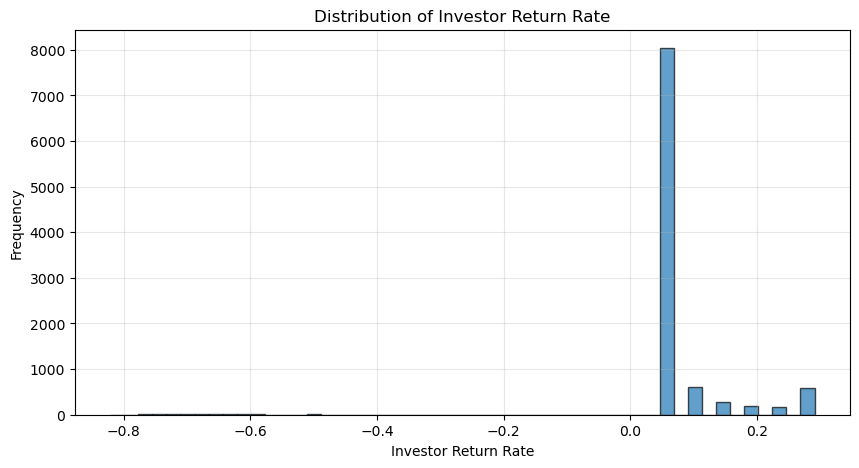

In [11]:
# ============================================================
# 3-9. Plot Investor Return Distribution
# ============================================================

plt.figure(figsize=(10, 5))
plt.hist(payoff_df["investor_return_rate"], bins=50, edgecolor="black", alpha=0.7)
plt.title("Distribution of Investor Return Rate")
plt.xlabel("Investor Return Rate")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.show()

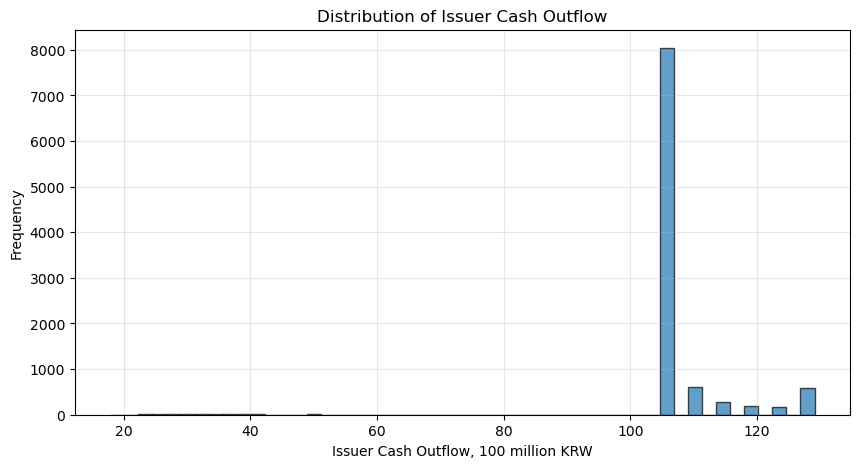

In [12]:
# ============================================================
# 3-10. Plot Issuer Cash Outflow Distribution
# ============================================================

plt.figure(figsize=(10, 5))
plt.hist(payoff_df["issuer_cash_outflow"] / 1e8, bins=50, edgecolor="black", alpha=0.7)
plt.title("Distribution of Issuer Cash Outflow")
plt.xlabel("Issuer Cash Outflow, 100 million KRW")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
# ============================================================
# 3-11. Settlement Timing Check
# ============================================================

settlement_summary = (
    payoff_df
    .groupby(["payoff_type", "autocall_no", "settlement_index"])
    .agg(
        count=("path_id", "count"),
        avg_elapsed_years=("elapsed_years", "mean"),
        avg_payoff=("investor_payoff", "mean")
    )
    .reset_index()
)

settlement_summary["probability"] = settlement_summary["count"] / len(payoff_df)

settlement_summary

,payoff_type,autocall_no,settlement_index,count,avg_elapsed_years,avg_payoff,probability
0,autocall_1,1,128,8038,0.500000,"10,485,000,000.000000",0.803800
1,autocall_2,2,257,607,1.000000,"10,970,000,000.000000",0.060700
2,autocall_3,3,388,272,1.500000,"11,455,000,000.000000",0.027200
3,autocall_4,4,518,202,2.000000,"11,940,000,000.000000",0.020200
4,autocall_5,5,650,164,2.500000,"12,425,000,000.000000",0.016400
5,autocall_6,6,779,129,3.000000,"12,910,000,000.000000",0.012900
6,maturity_knock_in_loss,0,779,130,3.000000,"3,510,873,749.160325",0.013000
7,maturity_no_knock_in,0,779,458,3.000000,"12,910,000,000.000000",0.045800


In [14]:
# ============================================================
# 3-12. Save Section 3 Outputs
# ============================================================

payoff_path = OUTPUT_DIR / "els_payoff_result.csv"
payoff_summary_path = OUTPUT_DIR / "els_payoff_summary_by_type.csv"
settlement_summary_path = OUTPUT_DIR / "els_settlement_summary.csv"

payoff_df.to_csv(payoff_path, index=False, encoding="utf-8-sig")
payoff_summary_by_type.to_csv(payoff_summary_path, index=False, encoding="utf-8-sig")
settlement_summary.to_csv(settlement_summary_path, index=False, encoding="utf-8-sig")

print("Saved payoff result to:", payoff_path)
print("Saved payoff summary to:", payoff_summary_path)
print("Saved settlement summary to:", settlement_summary_path)

Saved payoff result to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\els_payoff_result.csv
Saved payoff summary to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\els_payoff_summary_by_type.csv
Saved settlement summary to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\els_settlement_summary.csv


In [15]:
payoff_df

,path_id,autocall_occurred,autocall_no,settlement_index,elapsed_years,knock_in_occurred,final_price,min_price,payoff_type,investor_payoff,issuer_cash_outflow,investor_return_rate
0,0,True,1,128,0.500000,False,85.148390,73.958330,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
1,1,True,1,128,0.500000,False,382.028553,99.089556,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
2,2,True,1,128,0.500000,False,130.545363,83.432437,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
3,3,True,1,128,0.500000,False,88.593817,77.338565,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
4,4,True,1,128,0.500000,False,73.937730,73.937730,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,True,1,128,0.500000,False,67.094883,60.283054,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
9996,9996,True,1,128,0.500000,False,98.451087,79.432242,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
9997,9997,False,0,779,3.000000,True,50.229018,34.998732,maturity_knock_in_loss,"5,022,901,846.644485","5,022,901,846.644485",-0.497710
9998,9998,True,1,128,0.500000,False,58.875144,57.847763,autocall_1,"10,485,000,000.000000","10,485,000,000.000000",0.048500
